# 3. Treinamento em dez milhões de ASTs RAW/TANH

O corpus sorteia dez milhões de ASTs com até seis operações. Para cada AST, uma escolha com probabilidade 0,5 decide se `product_lags` será aplicado antes da canonização; a AST resultante é gravada em Parquet. O encoder recebe essa AST e o decoder prevê a forma ordenada correspondente, seja RAW ou protegida. O mesmo skeleton pertence a apenas uma partição; validação e teste retêm um exemplo por skeleton, então o número de exemplos de validação e de teste armazenados é menor que 10% e 20% de 10.000.000; as contagens reais ficam em `status.json` (`rows_by_split`). Os modelos Transformer preveem (1) o skeleton e (2) o skeleton junto com coeficientes.

Os coeficientes-alvo pertencem à AST escolhida. Ao gerar séries pelo método Shao–Wu, o gerador acrescenta um fator de escala certificado. A proteção seletiva é uma construção do projeto inspirada nas condições de Shao e Wu (2007, Theorem 5.1).


In [1]:
from pathlib import Path
import json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').exists())
CONFIG_PATH=ROOT/'configs/canonicalization_5m_raw_tanh.json'
RUN_DIR=ROOT/'experiments/canonicalization/outputs/raw_tanh'
config=json.loads(CONFIG_PATH.read_text(encoding='utf8'))
print(config)


{'experiment': 'canonical_ast_10m_raw_tanh_20261101', 'ast_count': 10000000, 'shard_size': 20000, 'generation_workers': 4, 'generator': {'minimum_operators': 1, 'maximum_operators': 6, 'num_series': 1, 'minimum_lag': 1, 'maximum_lag': 16, 'max_degree': 4, 'minimum_parameter_magnitude': 0.05, 'maximum_parameter_magnitude': 0.9}, 'data_seed': 20261101, 'split_seed': 20261102, 'training_seed': 20261103, 'protection_probability': 0.5, 'unique_eval_skeletons': True, 'split': {'train': 0.7, 'validation': 0.1, 'test': 0.2}, 'batch_size': 256, 'epochs': 10, 'patience': 3, 'learning_rate': 0.0005, 'weight_decay': 0.0001, 'coefficient_weight': 2.0, 'gradient_clip': 1.0, 'min_delta': 0.0001, 'max_decode_steps': 64, 'validation_examples_per_epoch': 10000, 'validation_greedy_size': 2048, 'coefficient_atol': 0.01, 'coefficient_rtol': 0.01, 'cpu_threads': 4, 'model': {'dimension': 96, 'heads': 4, 'encoder_layers': 2, 'dropout': 0.1, 'max_nodes': 20}, 'variants': [{'name': 'transformer_skeleton', 'enc

A configuração registra sementes, tamanho do corpus, separação disjunta por skeleton, deduplicação de validação e teste, arquitetura e métricas.

## Tamanho da entrada do Transformer: `max_nodes`

O encoder Transformer lê a AST como uma sequência em ordem prefixa: cada nó (operador, parâmetro, lag ou `tanh`) é um token, e cada posição da sequência tem um embedding de posição próprio. `max_nodes` é o tamanho dessa tabela, isto é, o **maior número de nós que uma AST de entrada pode ter**; uma AST maior não cabe e o treino falha.

Com $K$ operações binárias, uma AST tem $2K+1$ nós. A proteção `product_lags` pode envolver cada uma das até $K+1$ folhas de lag em uma `tanh`, somando até $K+1$ nós, e o limite fica em $3K+2$. Com $K=6$ são 13 nós sem proteção e até 20 com proteção. O limite não depende do número de lags; o tamanho do vocabulário, sim ($2L+5$ símbolos, 37 para $L=16$).


In [2]:
K = config['generator']['maximum_operators']
nodes_raw, nodes_protected = 2 * K + 1, 3 * K + 2
max_nodes = config['model']['max_nodes']
print(f'K={K} operações: até {nodes_raw} nós sem proteção, até {nodes_protected} nós com proteção; max_nodes={max_nodes}')
assert max_nodes >= nodes_protected, 'max_nodes é menor que a maior AST protegida possível'


K=6 operações: até 13 nós sem proteção, até 20 nós com proteção; max_nodes=20


In [3]:
import subprocess,sys,torch
status_file=RUN_DIR/'status.json'
finished=status_file.exists() and json.loads(status_file.read_text(encoding='utf8')).get('state')=='completed'
RETRAIN=False  # True apaga a decisão abaixo e repete o treino (cerca de 5 h em GPU)
if finished and not RETRAIN:
    print('Execução concluída encontrada em',RUN_DIR.relative_to(ROOT),'- o treino não será repetido.')
else:
    device='cuda' if torch.cuda.is_available() else 'cpu'
    command=[sys.executable,str(ROOT/'scripts/run_canonical_5m.py'),
             '--config',str(CONFIG_PATH.relative_to(ROOT)),
             '--run-dir',str(RUN_DIR.relative_to(ROOT)),
             '--device',device]
    print(' '.join(command))
    subprocess.run(command,cwd=ROOT,check=True)

Execução concluída encontrada em experiments\canonicalization\outputs\raw_tanh - o treino não será repetido.


O treino de dez milhões de ASTs foi executado em uma GPU (script `scripts/run_canonical_5m.py`) e a pasta da execução foi copiada para `experiments/canonicalization/outputs/raw_tanh/`. Esta célula só lê o registro; as tabelas e figuras abaixo vêm de `status.json` e de `manifest.json`.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
status=json.loads((RUN_DIR/'status.json').read_text(encoding='utf8'))
manifest=json.loads((RUN_DIR/'manifest.json').read_text(encoding='utf8'))
corpus=status['corpus']
splits=['train','validation','test']
table=pd.DataFrame({'linhas':corpus['rows_by_split'],
                    'skeletons distintos':corpus['distinct_skeletons_by_split'],
                    'com proteção sorteada':corpus['protection_selected_by_split'],
                    'com TANH inserido':corpus['tanh_inserted_by_split']}).loc[splits]
display(table)
print(f"sorteadas {corpus['sampled_asts']:,}; armazenadas {corpus['stored_examples']:,}; skeletons distintos no total {corpus['distinct_skeletons_total']:,}; skeletons em duas partições: {corpus['skeleton_overlap']}")
columns=['count','skeleton_exact','valid_rate','term_f1','joint_exact','coefficient_matched_mae','coefficient_union_rmse','best_epoch']
metrics=pd.DataFrame({name:{key:result.get(key) for key in columns} for name,result in status['results'].items()}).T
display(metrics)
provenance=manifest['provenance']
print(f"python {provenance['python']}, torch {provenance['torch']}, dispositivo {provenance['device']}, última invocação {provenance['elapsed_seconds']/3600:.2f} h")

,linhas,skeletons distintos,com proteção sorteada,com TANH inserido
train,6997384,6665377,3497775,3390899
validation,952965,952965,476553,474587
test,1905767,1905767,953714,949725


sorteadas 10,000,000; armazenadas 9,856,116; skeletons distintos no total 9,524,109; skeletons em duas partições: 0


,count,skeleton_exact,valid_rate,term_f1,joint_exact,coefficient_matched_mae,coefficient_union_rmse,best_epoch
transformer_skeleton,1905767.0,0.979441,0.991709,0.995608,NaN,NaN,NaN,10.0
transformer_joint,1905767.0,0.973169,0.986935,0.995042,0.042048,0.034771,0.190218,10.0


python 3.11.18, torch 2.6.0+cu124, dispositivo cuda:0, última invocação 4.90 h


A primeira tabela mostra que treino, validação e teste não compartilham nenhum skeleton. Validação e teste guardam um exemplo por skeleton; o treino mantém repetições (6.997.384 linhas, 6.665.377 skeletons distintos). A segunda tabela traz as métricas de geração livre sobre todas as 1.905.767 linhas de teste.

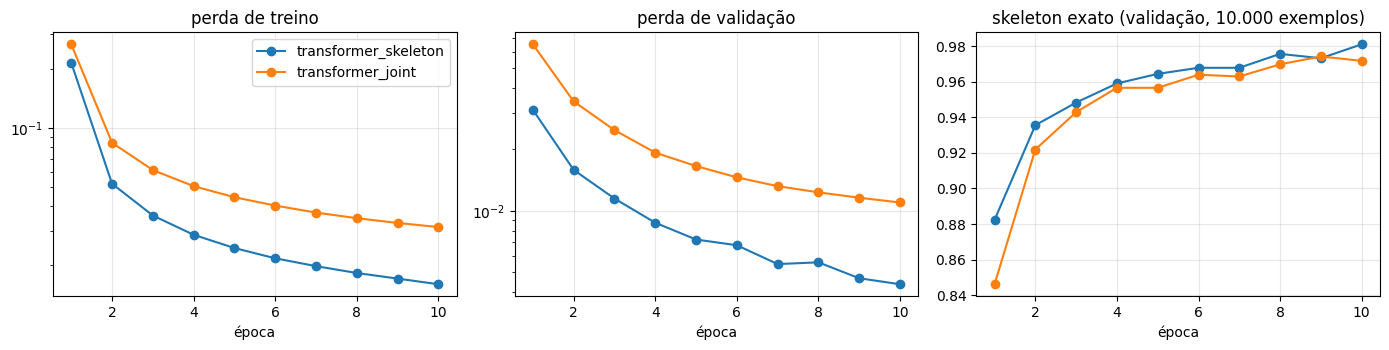

{'transformer_skeleton': 13.9, 'transformer_joint': 14.1} minutos por época


In [5]:
fig,axes=plt.subplots(1,3,figsize=(14,3.6))
for name,result in status['results'].items():
    history=pd.DataFrame(result['history'])
    axes[0].plot(history.epoch,history.train_loss,marker='o',label=name)
    axes[1].plot(history.epoch,history.validation_loss,marker='o',label=name)
    axes[2].plot(history.epoch,history.validation_skeleton_exact,marker='o',label=name)
for ax,title in zip(axes,['perda de treino','perda de validação','skeleton exato (validação, 10.000 exemplos)']):
    ax.set_title(title); ax.set_xlabel('época'); ax.grid(alpha=.3)
axes[0].set_yscale('log'); axes[1].set_yscale('log'); axes[0].legend()
plt.tight_layout(); plt.show()
epoch_minutes={name:pd.DataFrame(result['history']).seconds.mean()/60 for name,result in status['results'].items()}
print({name:round(value,1) for name,value in epoch_minutes.items()},'minutos por época')

As perdas de treino e de validação ainda caem na época 10 e a paciência de 3 épocas nunca disparou, então o limite de 10 épocas, e não a convergência, encerrou o treino. A curva de skeleton exato em validação usa uma amostra de 10.000 exemplos e oscila (por exemplo 0,9731 na época 9 e 0,9810 na 10); a métrica final vem do teste completo.

## Registro do experimento

**Pergunta:** os Transformers aprendem a converter ASTs RAW e protegidas em skeletons e coeficientes para skeletons ausentes no treino? **Configuração:** `configs/canonicalization_5m_raw_tanh.json` (SHA-256 `e05ed2d0…48ed24`), com 10.000.000 ASTs sorteadas pelo amostrador combinatório, probabilidade de proteção 0,5, uma série, lags 1–16, 1–6 operações, grau máximo 4, `max_nodes` 20 (tamanho máximo da entrada do Transformer, 3K+2 nós com K=6), vocabulário de 37 símbolos, divisão 70/10/20 por hash do skeleton, validação e teste com um exemplo por skeleton; encoder Transformer de 2 camadas, dimensão 96, 4 cabeças, decoder GRU com atenção; 10 épocas, lote 256, AdamW com taxa 5×10⁻⁴ e decaimento 10⁻⁴, paciência 3, peso 2 para a perda dos coeficientes. **Seeds:** dados 20261101, divisão 20261102 e treino 20261103. **Execução:** GPU `cuda:0`, Python 3.11.18, torch 2.6.0+cu124; a última invocação durou 4,90 h (as partições Parquet já estavam geradas e foram reaproveitadas), com cerca de 13,9 min por época na variante de skeleton e 14,1 min na variante conjunta, e cerca de 7 min para avaliar cada modelo no teste. **Proveniência:** commit `6fb7621e3633cf4c5734ddacf24f244348c4f4e5` do repositório (os cinco arquivos-fonte registrados em `manifest.json` conferem com esse commit); modelos e corpus publicados em `mateuswiteck/tsfmxai-canonicalization-encoder-decoder` e `mateuswiteck/tsfmxai-canonicalization-asts` no Hugging Face, com os parâmetros do gerador nos metadados. **Métricas:** skeleton exato, taxa de saída válida, F1 por termo, acerto conjunto (skeleton e todos os coeficientes com tolerância absoluta e relativa de 0,01), erro dos coeficientes e contagens por partição. **Resultados:** corpus de 9.856.116 linhas armazenadas (treino 6.997.384, validação 952.965, teste 1.905.767), 9.524.109 skeletons distintos e nenhum skeleton em duas partições; 3.497.775 ASTs de treino com proteção sorteada e 3.390.899 com TANH inserido. No teste completo (1.905.767 skeletons ausentes do treino), a variante de skeleton obteve skeleton exato 0,9794, saída válida 0,9917 e F1 por termo 0,9956; a variante conjunta obteve 0,9732, 0,9869 e 0,9950, acerto conjunto de apenas 0,0420, erro absoluto médio de 0,0348 nos coeficientes dos termos acertados e RMSE de 0,190 sobre a união dos termos. Ambas atingiram o melhor resultado na época 10, a última. **Resumo científico:** os Transformers aproximam a canonização de ASTs RAW e protegidas em skeletons nunca vistos, com cerca de 97–98% de acerto exato, mas não calculam os coeficientes com precisão: menos de 5% dos exemplos têm todos os coeficientes dentro de 1%, e a cabeça de coeficientes custa cerca de 0,6 ponto percentual de acerto estrutural. Como as perdas ainda caíam na época 10 e a paciência não disparou, os valores são limites inferiores para este orçamento de épocas, e a métrica por época em validação, calculada em 10.000 exemplos, é ruidosa. **Reprodução:** `.venv/Scripts/python.exe -m jupyter nbconvert --to notebook --execute --inplace experiments/canonicalization/06_train.ipynb` lê a execução existente sem treinar de novo; para repetir o treino, em uma máquina com GPU use `python scripts/run_canonical_5m.py --device cuda --release-dir experiments/canonicalization/outputs/release/canonical_ast` a partir do commit acima, ou `RETRAIN=True` neste notebook.